In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder

from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier, VotingClassifier, StackingClassifier

from sklearn.metrics import accuracy_score, recall_score, classification_report

In [2]:
df = pd.read_csv("novagen_dataset.csv")

In [3]:
df.head()
df.isnull().sum()
df.info()
df.describe()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9549 entries, 0 to 9548
Data columns (total 23 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   Age                    9549 non-null   float64
 1   BMI                    9549 non-null   float64
 2   Blood_Pressure         9549 non-null   float64
 3   Cholesterol            9549 non-null   float64
 4   Glucose_Level          9549 non-null   float64
 5   Heart_Rate             9549 non-null   float64
 6   Sleep_Hours            9549 non-null   float64
 7   Exercise_Hours         9549 non-null   float64
 8   Water_Intake           9549 non-null   float64
 9   Stress_Level           9549 non-null   float64
 10  Target                 9549 non-null   int64  
 11  Smoking                9549 non-null   int64  
 12  Alcohol                9549 non-null   int64  
 13  Diet                   9549 non-null   int64  
 14  MentalHealth           9549 non-null   int64  
 15  Phys

,Age,BMI,Blood_Pressure,Cholesterol,Glucose_Level,Heart_Rate,Sleep_Hours,Exercise_Hours,Water_Intake,Stress_Level,Target,Smoking,Alcohol,Diet,MentalHealth,PhysicalActivity,MedicalHistory,Allergies
count,9549.000000,9549.000000,9549.000000,9549.000000,9549.000000,9549.000000,9549.000000,9549.000000,9549.000000,9549.000000,9549.000000,9549.000000,9549.000000,9549.000000,9549.000000,9549.000000,9549.000000,9549.000000
mean,33.806786,25.660697,130.382658,199.091528,100.225678,73.613782,6.951409,1.892345,3.580899,4.382134,0.521416,0.990470,0.995183,1.005864,0.998429,1.003351,1.004713,0.989318
std,24.566473,1.942369,27.878476,1.969234,2.157999,1.681538,2.352152,1.378714,1.622874,2.078593,0.499567,0.815521,0.816653,0.815877,0.821844,0.808800,0.813506,0.815699
min,0.000000,19.000000,22.000000,192.000000,93.000000,67.000000,0.000000,-0.000000,-0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,14.000000,24.000000,113.000000,198.000000,99.000000,73.000000,5.000000,1.000000,2.000000,3.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
50%,29.000000,26.000000,134.000000,199.000000,100.000000,74.000000,7.000000,2.000000,4.000000,4.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000
75%,50.000000,27.000000,150.000000,200.000000,102.000000,75.000000,9.000000,3.000000,5.000000,6.000000,1.000000,2.000000,2.000000,2.000000,2.000000,2.000000,2.000000,2.000000
max,100.000000,32.000000,225.000000,207.000000,107.000000,80.000000,14.000000,8.000000,10.000000,12.000000,1.000000,2.000000,2.000000,2.000000,2.000000,2.000000,2.000000,2.000000


# EDA - eploratory data analysis

Text(0.5, 1.0, 'is healthy or not?')

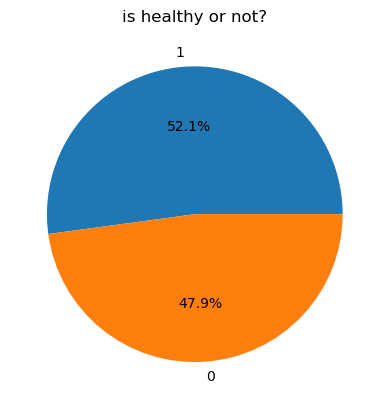

In [4]:
# How balanced our classes are?

classes_cnt = df["Target"].value_counts()
plt.pie(classes_cnt, labels=classes_cnt.index, autopct="%1.1f%%")
plt.title("is healthy or not?")

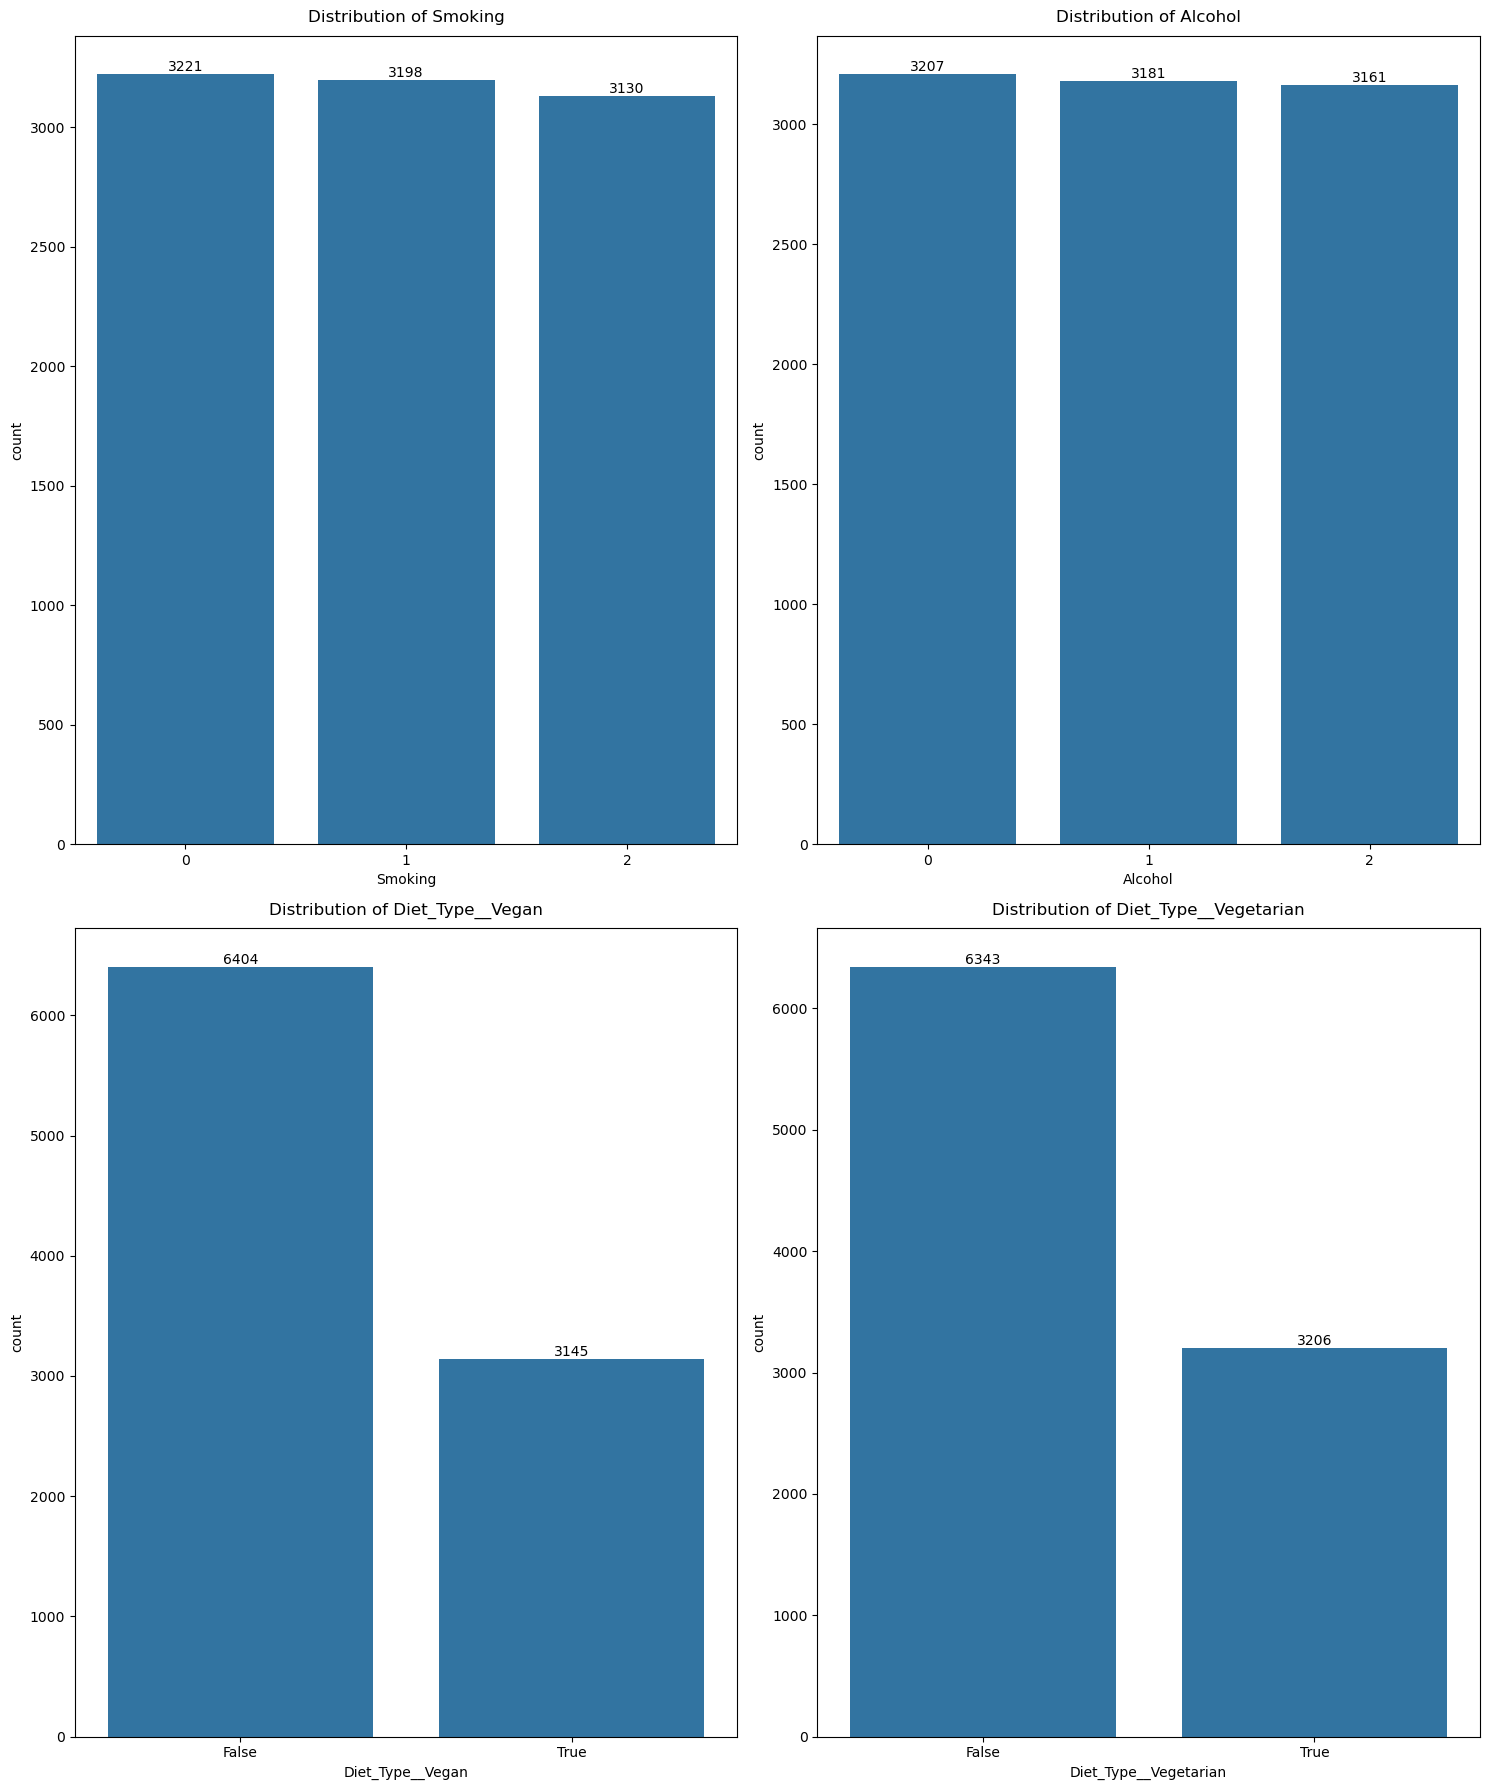

In [5]:
# Analysis Classes

cols = ["Smoking", "Alcohol", "Diet_Type__Vegan", "Diet_Type__Vegetarian"]

figure, axes = plt.subplots(nrows=2, ncols=2, figsize=(15, 18))
axes = axes.flatten()

for i, col in enumerate(cols):
    ax = axes[i]
    classes_cnt = df[col].value_counts()

    sns.barplot(classes_cnt, ax=ax)
    ax.bar_label(ax.containers[0])
    ax.set_title(f"Distribution of {col}", fontsize=12, pad=10)

plt.tight_layout()
plt.show()

<Axes: xlabel='Age', ylabel='Count'>

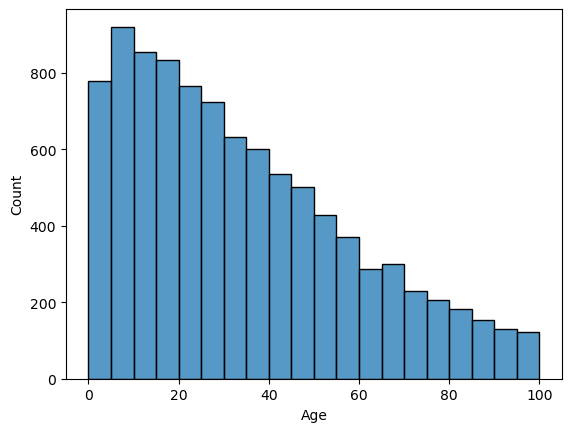

In [6]:
# Analysis age

sns.histplot(
    data=df,
    x="Age",
    bins=20
)

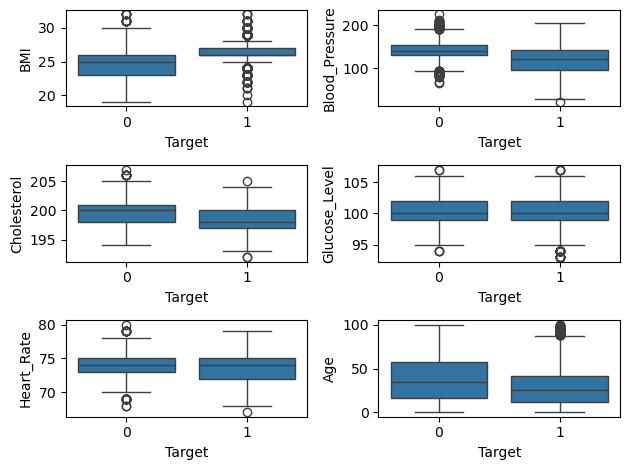

In [7]:
# Outlier

figure, axes = plt.subplots(3, 2)

sns.boxplot(ax=axes[0, 0], data=df, x="Target", y="BMI")
sns.boxplot(ax=axes[0, 1], data=df, x="Target", y="Blood_Pressure")
sns.boxplot(ax=axes[1, 0], data=df, x="Target", y="Cholesterol")
sns.boxplot(ax=axes[1, 1], data=df, x="Target", y="Glucose_Level")
sns.boxplot(ax=axes[2, 0], data=df, x="Target", y="Heart_Rate")
sns.boxplot(ax=axes[2, 1], data=df, x="Target", y="Age")

plt.tight_layout()

# Encoding

In [8]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9549 entries, 0 to 9548
Data columns (total 23 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   Age                    9549 non-null   float64
 1   BMI                    9549 non-null   float64
 2   Blood_Pressure         9549 non-null   float64
 3   Cholesterol            9549 non-null   float64
 4   Glucose_Level          9549 non-null   float64
 5   Heart_Rate             9549 non-null   float64
 6   Sleep_Hours            9549 non-null   float64
 7   Exercise_Hours         9549 non-null   float64
 8   Water_Intake           9549 non-null   float64
 9   Stress_Level           9549 non-null   float64
 10  Target                 9549 non-null   int64  
 11  Smoking                9549 non-null   int64  
 12  Alcohol                9549 non-null   int64  
 13  Diet                   9549 non-null   int64  
 14  MentalHealth           9549 non-null   int64  
 15  Phys

In [9]:
cols = df.select_dtypes(include="bool").columns
le = LabelEncoder()

df["Diet_Type__Vegan"] = le.fit_transform(df["Diet_Type__Vegan"])
df["Diet_Type__Vegetarian"] = le.fit_transform(df["Diet_Type__Vegetarian"])
df["Blood_Group_AB"] = le.fit_transform(df["Blood_Group_AB"])
df["Blood_Group_B"] = le.fit_transform(df["Blood_Group_B"])
df["Blood_Group_O"] = le.fit_transform(df["Blood_Group_O"])

# Correlation Heatmap

<Axes: >

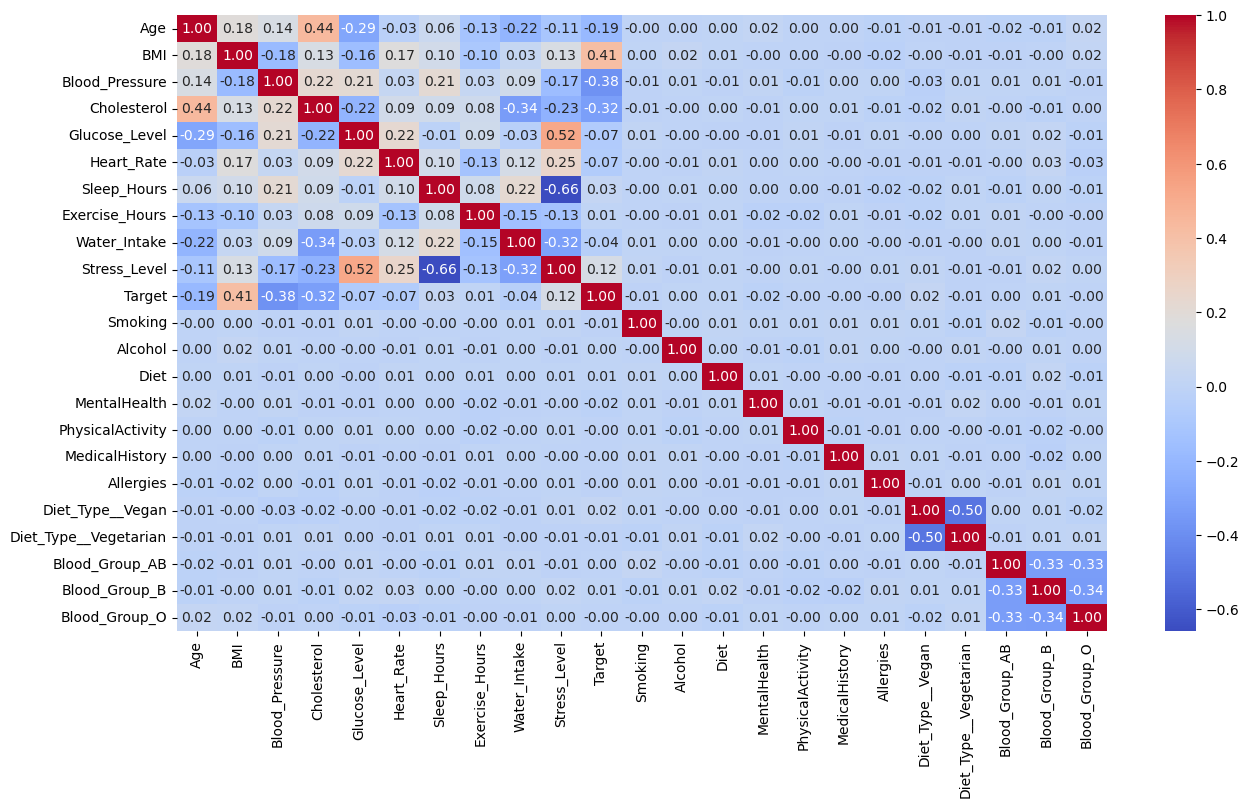

In [10]:
num_cols = df.select_dtypes(include="number").columns
corr_matrix = df[num_cols].corr()

plt.figure(figsize=(15,8))

sns.heatmap(
    corr_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm"
)

# Train_Test_Split + Feature Scaling

In [11]:
X = df.drop("Target", axis=1)
y = df["Target"]

In [12]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

In [13]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Logistic Regression

In [14]:
log_reg = LogisticRegression(
    penalty="l2",
    solver="liblinear",
    max_iter=1000
)

log_reg.fit(X_train_scaled, y_train)

y_pred = log_reg.predict(X_test_scaled)

print(f"Accuracy: {accuracy_score(y_test, y_pred)}")
print(f"Recall: {recall_score(y_test, y_pred)}")
print(classification_report(y_test, y_pred))

Accuracy: 0.8225130890052356
Recall: 0.8376237623762376
              precision    recall  f1-score   support

           0       0.82      0.81      0.81       900
           1       0.83      0.84      0.83      1010

    accuracy                           0.82      1910
   macro avg       0.82      0.82      0.82      1910
weighted avg       0.82      0.82      0.82      1910



# KNN

In [15]:
knn = KNeighborsClassifier(
    n_neighbors=5,
    metric="euclidean"
)

knn.fit(X_train_scaled, y_train)

y_pred = knn.predict(X_test_scaled)

print(f"Accuracy: {accuracy_score(y_test, y_pred)}")
print(f"Recall: {recall_score(y_test, y_pred)}")
print(classification_report(y_test, y_pred))

Accuracy: 0.8717277486910995
Recall: 0.8693069306930693
              precision    recall  f1-score   support

           0       0.86      0.87      0.87       900
           1       0.89      0.87      0.88      1010

    accuracy                           0.87      1910
   macro avg       0.87      0.87      0.87      1910
weighted avg       0.87      0.87      0.87      1910



# Random Forest

In [16]:
rf = RandomForestClassifier(
    n_estimators=201,
    oob_score=True,
    max_depth=None,
    random_state=42
)

rf.fit(X_train_scaled, y_train)

y_pred = rf.predict(X_test_scaled)

print(f"Accuracy: {accuracy_score(y_test, y_pred)}")
print(f"Recall: {recall_score(y_test, y_pred)}")
print(classification_report(y_test, y_pred))

Accuracy: 0.9434554973821989
Recall: 0.9455445544554455
              precision    recall  f1-score   support

           0       0.94      0.94      0.94       900
           1       0.95      0.95      0.95      1010

    accuracy                           0.94      1910
   macro avg       0.94      0.94      0.94      1910
weighted avg       0.94      0.94      0.94      1910



# Gradient Boosting

In [17]:
gb = GradientBoostingClassifier(
    n_estimators=100,
    learning_rate=0.1,
    max_depth=3,
    random_state=42
)

gb.fit(X_train_scaled, y_train)

y_pred = gb.predict(X_test_scaled)

print(f"Accuracy: {accuracy_score(y_test, y_pred)}")
print(f"Recall: {recall_score(y_test, y_pred)}")
print(classification_report(y_test, y_pred))

Accuracy: 0.9183246073298429
Recall: 0.9247524752475248
              precision    recall  f1-score   support

           0       0.92      0.91      0.91       900
           1       0.92      0.92      0.92      1010

    accuracy                           0.92      1910
   macro avg       0.92      0.92      0.92      1910
weighted avg       0.92      0.92      0.92      1910



# Voting Classifier

In [18]:
voting_clf = VotingClassifier(
    estimators=[
        ("lr", LogisticRegression(max_iter=1000, solver="liblinear")),
        ("knn", KNeighborsClassifier(n_neighbors=5)),
        ("rf", RandomForestClassifier(n_estimators=201, random_state=42))
    ],
    voting="soft"
)

voting_clf.fit(X_train_scaled, y_train)

y_pred = voting_clf.predict(X_test_scaled)

print(f"Accuracy: {accuracy_score(y_test, y_pred)}")
print(f"Recall: {recall_score(y_test, y_pred)}")
print(classification_report(y_test, y_pred))

Accuracy: 0.9167539267015706
Recall: 0.9277227722772278
              precision    recall  f1-score   support

           0       0.92      0.90      0.91       900
           1       0.92      0.93      0.92      1010

    accuracy                           0.92      1910
   macro avg       0.92      0.92      0.92      1910
weighted avg       0.92      0.92      0.92      1910



# Stacking Classifier

In [19]:
stacking_clf = StackingClassifier(
    estimators=[
        ("lr", LogisticRegression(max_iter=1000, solver="liblinear")),
        ("knn", KNeighborsClassifier(n_neighbors=5)),
        ("rf", RandomForestClassifier(n_estimators=201, random_state=42))
    ],
    final_estimator = LogisticRegression(max_iter=1000, solver="liblinear"),
    cv=5
)

stacking_clf.fit(X_train_scaled, y_train)

y_pred = stacking_clf.predict(X_test_scaled)

print(f"Accuracy: {accuracy_score(y_test, y_pred)}")
print(f"Recall: {recall_score(y_test, y_pred)}")
print(classification_report(y_test, y_pred))

Accuracy: 0.9434554973821989
Recall: 0.9396039603960396
              precision    recall  f1-score   support

           0       0.93      0.95      0.94       900
           1       0.95      0.94      0.95      1010

    accuracy                           0.94      1910
   macro avg       0.94      0.94      0.94      1910
weighted avg       0.94      0.94      0.94      1910



## Results

| Model                | Recall |
|----------------------|:------:|
| Logistic Regression  | 83.8%  |
| KNN                  | 85.7%  |
| Random Forest        | 94.6%  |
| Gradient Boosting    | 92.3%  |
| Voting Classifier    | 92.5% |
| Stacking Classifier  | 94.05% |

### Best Classifier that we should use for NovaGen(based on Recall) - Random Forest with accuracy of 94.6%